# 03 · Ngành hàng — Quyết định ②: tập trung thúc đẩy ngành hàng nào?

Notebook giải trình cho trang Power BI **p2 "Ngành hàng"**.

| # | Câu hỏi | Mục |
|---|---|---|
| 1 | Doanh thu sản phẩm đang ở quy mô nào; kỳ này so với cùng kỳ và quý trước ra sao? | §1 |
| 2 | Ngành hàng nào tạo ra doanh thu? Ngành đó bán nhờ số lượng hay nhờ giá? | §2 |
| 3 | **Ngành nào là trụ cột, ngành nào đang lên, ngành nào đang đi xuống?** | §3 |
| 4 | Cơ cấu ngành có thay đổi theo thời gian / mùa vụ không? | §4 |
| 5 | Doanh thu đến từ hàng rẻ hay hàng đắt? Phí ship chiếm bao nhiêu ở mỗi tầng giá? | §5 |
| 6 | Ngành nào doanh thu cao nhưng chất lượng kém? Hàng cồng kềnh có gắn với giao trễ không? | §6 |
| 7 | Doanh thu dựa vào vài sản phẩm "hit" hay vào cái đuôi dài? | §7 |

§8 đối chiếu với Gold, §9 chỉ rõ biểu đồ nào đứng sau visual nào trên trang p2.

### Quy ước

- **Tập đơn:** mọi biểu đồ tính trên **dòng sản phẩm thuộc đơn hợp lệ** (đơn có sản phẩm, trạng thái khác `canceled` / `unavailable`), trừ khi tiêu đề ghi khác.
- **Doanh thu (GMV)** = `price + freight_value` (BRL). **Doanh thu hàng** = `price`.
  **Giá sản phẩm** (tầng giá, giá TB) dùng `price`, không gồm phí ship.
- **Sản phẩm (SKU)** = `product_id`. **Số sản phẩm đã bán** = số dòng trong `fact_order_items` (1 dòng = 1 sản phẩm; khác với số SKU).
- **Ngành hàng** = tên tiếng Anh, thiếu thì tên gốc, thiếu cả hai thì `unknown` (`CATEGORY_SQL`, giống `category` của Gold `fact_item_sales`).
- **Kỳ so sánh** (cùng quy tắc với Gold / Power BI, in ở §0): kỳ này = 01 → tháng báo cáo suy từ dữ liệu, so với cùng các tháng năm trước (YoY);
  QoQ = quý chứa tháng báo cáo so với cùng khoảng lùi 3 tháng. Ghi đè kỳ bằng `REPORT_START` / `REPORT_END`.
  Biểu đồ theo tháng dùng cửa sổ xu hướng 01/năm trước → tháng báo cáo.

## 0. Kết nối lakehouse & nạp dữ liệu Silver

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from common import *   # kết nối, kỳ phân tích, bảng màu, hàm trục, KPI, item_ps

con, P = connect(["dim_seller", "dim_product", "dim_category"])
apply_theme()

Kỳ này 01–08/2018 | cùng kỳ 01–08/2017 | quý 07–08/2018 vs 04–05/2018 | xu hướng 01/2017–08/2018 | 98,059 đơn, 96,817 đơn hợp lệ


In [2]:
# ---------- Ngưỡng phân tích (khai báo một lần, dùng cho mọi phần) ----------
MIN_CATEGORY_SHARE = GOLD.MIN_CATEGORY_SHARE   # ngành được đưa vào scatter / ma trận: ≥ 0,5% GMV (= in_matrix của Gold)
GROWTH_AXIS_CAP = 6.0             # trục Y ma trận tăng trưởng: ngành > +600% vẽ ở mép trên
TOP_CATEGORY_N = len(CATEGORY_COLORS)   # số ngành riêng trong biểu đồ cơ cấu theo tháng (mỗi ngành 1 màu, còn lại = Khác)
PRICE_EDGES = band_edges(GOLD.PRICE_BANDS)                       # giá / đơn vị (BRL)
SKU_UNIT_EDGES = band_edges(GOLD.SKU_UNIT_BANDS)                 # tổng số sản phẩm đã bán của SKU (khoảng đóng bên phải)
SKU_UNIT_LABELS = band_order(GOLD.SKU_UNIT_BANDS)
PRICE_LABELS = band_labels(PRICE_EDGES)

def quadrant(x_high, y_high, names) -> np.ndarray:
    # names = (cao-cao, cao-thấp, thấp-cao, thấp-thấp) theo (trục X, trục Y)
    x_high, y_high = np.asarray(x_high), np.asarray(y_high)
    return np.select([x_high & y_high, x_high & ~y_high, ~x_high & y_high], names[:3], names[3])

def share_bars(ax, categories, left, right, left_label, right_label="% GMV", left_text=None):
    # Cặp cột tỷ trọng: một chỉ số "số lượng" (xám) cạnh % GMV (xanh)
    x = np.arange(len(categories)); width = 0.38
    left_bars = ax.bar(x - width / 2, left, width, color=C_GREY, label=left_label)
    right_bars = ax.bar(x + width / 2, right, width, color=C_MAIN, label=right_label)
    ax.bar_label(left_bars, labels=left_text or [f"{v:.0%}" for v in left], fontsize=8.5, padding=2)
    ax.bar_label(right_bars, labels=[f"{v:.0%}" for v in right], fontsize=8.5, padding=2)
    ax.set_xticks(x, categories); pct_axis(ax); ax.legend()
    ax.set_ylim(0, max(max(left), max(right)) * 1.25)

### Tạo bảng phân tích
- `item_ps`: **1 dòng / đơn vị sản phẩm trong đơn hợp lệ**: thời gian mua, ngành, SKU, người bán (bang/vùng), khách (bang), giá, phí ship, GMV.
  Tạo bằng `create_item_ps()` của `common/tables.py`, dùng chung với notebook `05_seller` nên hai notebook ra cùng con số.
- `MARKET_GROWTH`: tăng trưởng GMV toàn sàn kỳ này so với cùng kỳ năm trước, dùng làm đường tham chiếu ở §3 và §5.

In [3]:
create_item_ps()
yoy_totals = q(f"SELECT sum(CASE WHEN {P.prev} THEN gmv END) AS prev, sum(CASE WHEN {P.cur} THEN gmv END) AS cur FROM item_ps").iloc[0]
MARKET_GROWTH = yoy_totals.cur / yoy_totals.prev - 1

print(q("""SELECT count(*) AS valid_items, count(DISTINCT order_key) AS valid_orders, count(DISTINCT product_id) AS skus,
                  count(DISTINCT seller_key) AS sellers, count(DISTINCT category) AS categories,
                  round(sum(gmv) / 1e6, 2) AS gmv_mil
           FROM item_ps""").to_string(index=False))
print(f"Tăng trưởng GMV toàn sàn {P.label_cur} vs {P.label_prev}: {MARKET_GROWTH:+.1%}")

 valid_items  valid_orders  skus  sellers  categories  gmv_mil
      110500         96817 32399     3042          74    15.53
Tăng trưởng GMV toàn sàn 01–08/2018 vs 01–08/2017: +135.6%


## 1. KPI sản phẩm
*Câu hỏi: "Doanh thu sản phẩm đang ở quy mô nào? Kỳ này so với cùng kỳ năm trước và quý trước thế nào?"*

Ba dòng cuối là các thẻ chất lượng của trang p2: điểm review TB (đơn hợp lệ) và tỷ lệ hủy đơn (đơn `canceled`/`unavailable` / mọi đơn).

In [4]:
def product_kpis(where: str) -> dict:
    k = q(f"""SELECT sum(gmv) AS gmv, sum(price) AS product_rev, sum(freight_value) / sum(gmv) AS freight_share,
                     count(*) AS units, avg(price) AS avg_price,
                     count(DISTINCT category) AS categories, count(DISTINCT product_id) AS skus
              FROM item_ps WHERE {where}""").iloc[0].to_dict()
    k.update(q(f"""SELECT avg(CASE WHEN is_valid = 1 THEN review_score END) AS avg_review, avg(is_lost) AS cancel_rate
                    FROM order_base WHERE {where}""").iloc[0].to_dict())
    k["gmv_per_sku"] = k["gmv"] / k["skus"]
    k["units_per_sku"] = k["units"] / k["skus"]
    return k

KPIS = [
    Kpi("gmv", "Doanh thu GMV (BRL)", "{:,.0f}", "pct"),
    Kpi("product_rev", "Doanh thu hàng (BRL)", "{:,.0f}", "pct"),
    Kpi("freight_share", "Tỷ trọng phí ship / GMV", "{:.1%}", "pp"),
    Kpi("units", "Số sản phẩm đã bán", "{:,.0f}", "pct"),
    Kpi("avg_price", "Giá bán TB / đơn vị (BRL)", "{:,.1f}", "pct"),
    Kpi("categories", "Số ngành có doanh thu", "{:,.0f}", "pct"),
    Kpi("skus", "Số SKU có doanh thu", "{:,.0f}", "pct"),
    Kpi("units_per_sku", "Số sản phẩm đã bán / SKU", "{:,.2f}", "pct"),
    Kpi("gmv_per_sku", "GMV / SKU (BRL)", "{:,.0f}", "pct"),
    Kpi("avg_review", "Điểm review TB", "{:.2f}", "abs"),
    Kpi("cancel_rate", "Tỷ lệ hủy đơn", "{:.2%}", "pp"),
]
kpi_table(KPIS, product_kpis, P)

,01–08/2017,01–08/2018,Thay đổi YoY,Quý trước (04–05/2018),Quý này (07–08/2018),Thay đổi QoQ
Chỉ số,,,,,,
Doanh thu GMV (BRL),"3,564,588","8,398,428",+135.6%,"2,228,699","1,939,839",-13.0%
Doanh thu hàng (BRL),"3,072,398","7,176,624",+133.6%,"1,923,795","1,645,829",-14.4%
Tỷ trọng phí ship / GMV,13.8%,14.5%,+0.74 điểm %,13.7%,15.2%,+1.48 điểm %
Số sản phẩm đã bán,"25,453","59,685",+134.5%,"15,322","13,525",-11.7%
Giá bán TB / đơn vị (BRL),120.7,120.2,-0.4%,125.6,121.7,-3.1%
Số ngành có doanh thu,71,73,+2.8%,70,68,-2.9%
Số SKU có doanh thu,"9,754","20,028",+105.3%,"6,949","7,129",+2.6%
Số sản phẩm đã bán / SKU,2.61,2.98,+14.2%,2.20,1.90,-14.0%
GMV / SKU (BRL),365,419,+14.7%,321,272,-15.2%


> **🔎 Kết quả chính**
> - **01–08/2018 so với cùng kỳ**: GMV **+135,6%** gần bằng số sản phẩm đã bán **+134,5%**, còn **giá bán TB / đơn vị đứng yên (R$ 120, −0,4%)** → tăng trưởng đến **hoàn toàn từ số lượng**.
> - Số SKU tăng +105%, chậm hơn doanh thu, nên mỗi SKU bán được nhiều hơn (GMV / SKU +14,7%). Tỷ trọng phí ship / GMV nhích 13,8% → 14,5%.
> - Thẻ chất lượng p2: điểm review 4,18 → 4,11; **tỷ lệ hủy đơn giảm một nửa, 1,77% → 0,87%**.
> - **QoQ (07–08 so với 04–05/2018)**: GMV −13,0%, số sản phẩm −11,7%, GMV / SKU −15,2%; phí ship / GMV 13,7% → 15,2% và tỷ lệ hủy 0,45% → 1,23% cùng tăng.

## 2. Cơ cấu doanh thu theo ngành hàng
*Câu hỏi: "Ngành nào tạo ra doanh thu? Ngành đó bán được nhờ **số lượng** hay nhờ **giá**?"*

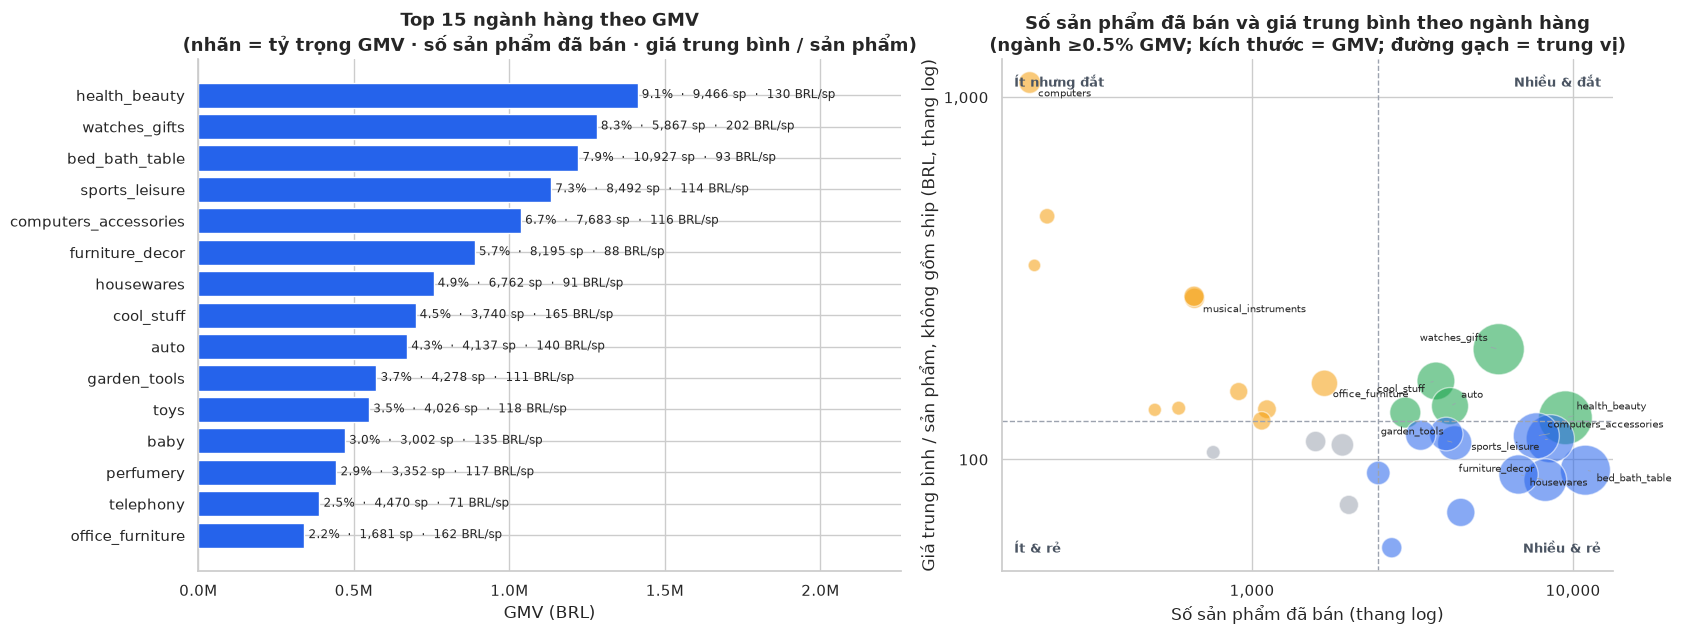

Tổng 74 ngành. Top 5 = 39.2%, top 10 = 62.3%, số ngành đạt 80% GMV = 18
Trung vị (ngành ≥0.5% GMV): 2,473 sản phẩm, giá TB R$ 128
               n  gmv_share                                                                examples
group                                                                                              
Nhiều & rẻ    11   0.481080  bed_bath_table, sports_leisure, computers_accessories, furniture_decor
Nhiều & đắt    5   0.292119                          health_beauty, watches_gifts, cool_stuff, auto
Ít & rẻ        4   0.046890            pet_shop, unknown, fashion_bags_accessories, home_appliances
Ít nhưng đắt  11   0.119509      office_furniture, computers, musical_instruments, small_appliances
      category  units  avg_price
 watches_gifts   5867      201.6
bed_bath_table  10927       93.4
     computers    203     1098.3


In [5]:
categories = q("""SELECT category, sum(gmv) AS gmv, sum(price) AS product_rev, count(*) AS units,
                         count(DISTINCT product_id) AS skus, count(DISTINCT seller_key) AS sellers, avg(price) AS avg_price
                  FROM item_ps GROUP BY 1 ORDER BY gmv DESC""")
categories["share"] = categories.gmv / categories.gmv.sum()
categories["cum_share"] = categories.share.cumsum()

TOP_BAR_N = 15
top_categories = categories.head(TOP_BAR_N).iloc[::-1]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.15, 1]})
category_bars = ax1.barh(top_categories.category, top_categories.gmv, color=C_MAIN)
ax1.bar_label(category_bars, labels=[f"{s:.1%}  ·  {u:,} sp  ·  {p:,.0f} BRL/sp"
                                     for s, u, p in zip(top_categories.share, top_categories.units, top_categories.avg_price)],
              padding=3, fontsize=8.5)
brl_axis(ax1, "x"); ax1.set_xlim(0, top_categories.gmv.max() * 1.6)
ax1.set_title(f"Top {TOP_BAR_N} ngành hàng theo GMV\n(nhãn = tỷ trọng GMV · số sản phẩm đã bán · giá trung bình / sản phẩm)")
ax1.set_xlabel("GMV (BRL)")

# Bản đồ "số lượng × giá": chỉ ngành đủ lớn
VOLUME_PRICE_NAMES = ("Nhiều & đắt", "Nhiều & rẻ", "Ít nhưng đắt", "Ít & rẻ")
VOLUME_PRICE_COLORS = dict(zip(VOLUME_PRICE_NAMES, [C_GOOD, C_MAIN, C_ACCENT, C_GREY]))
major = categories[categories.share >= MIN_CATEGORY_SHARE].copy()
median_units, median_price = major.units.median(), major.avg_price.median()
major["group"] = quadrant(major.units >= median_units, major.avg_price >= median_price, VOLUME_PRICE_NAMES)
ax2.scatter(major.units, major.avg_price, s=major.gmv / major.gmv.max() * 1500, alpha=0.55,
            c=major.group.map(VOLUME_PRICE_COLORS), edgecolor="white")
ax2.axvline(median_units, color=C_GREY, ls="--", lw=1); ax2.axhline(median_price, color=C_GREY, ls="--", lw=1)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax2.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v:,.0f}"))
for j, (_, r) in enumerate(major.nlargest(10, "gmv").iterrows()):
    ax2.annotate(r.category, (r.units, r.avg_price), fontsize=7.5, ha="right" if j % 2 else "left",
                 xytext=(-8 if j % 2 else 8, 6 if j % 4 < 2 else -8), textcoords="offset points",
                 arrowprops=dict(arrowstyle="-", color=C_GREY, lw=0.5))
for _, r in major[major.group == "Ít nhưng đắt"].nlargest(3, "gmv").iterrows():
    ax2.annotate(r.category, (r.units, r.avg_price), fontsize=7.5, xytext=(6, -10), textcoords="offset points")
for (x, y, name) in [(0.98, 0.97, "Nhiều & đắt"), (0.02, 0.97, "Ít nhưng đắt"), (0.98, 0.03, "Nhiều & rẻ"), (0.02, 0.03, "Ít & rẻ")]:
    ax2.text(x, y, name, transform=ax2.transAxes, ha="right" if x > 0.5 else "left", va="top" if y > 0.5 else "bottom",
             fontsize=9, color=C_MUTED_TEXT, fontweight="bold")
ax2.set_xlabel("Số sản phẩm đã bán (thang log)"); ax2.set_ylabel("Giá trung bình / sản phẩm, không gồm ship (BRL, thang log)")
ax2.set_title(f"Số sản phẩm đã bán và giá trung bình theo ngành hàng\n(ngành ≥{MIN_CATEGORY_SHARE:.1%} GMV; kích thước = GMV; đường gạch = trung vị)")
plt.tight_layout(); plt.show()

print(f"Tổng {len(categories)} ngành. Top 5 = {categories.share.head(5).sum():.1%}, top 10 = {categories.share.head(10).sum():.1%}, "
      f"số ngành đạt 80% GMV = {(categories.cum_share < 0.8).sum() + 1}")
print(f"Trung vị (ngành ≥{MIN_CATEGORY_SHARE:.1%} GMV): {median_units:,.0f} sản phẩm, giá TB R$ {median_price:,.0f}")
print(major.groupby("group").agg(n=("category", "size"), gmv_share=("share", "sum"),
                                 examples=("category", lambda s: ", ".join(s.head(4)))).to_string())
print(major.loc[major.category.isin(["computers", "watches_gifts", "bed_bath_table"]), ["category", "units", "avg_price"]].round(1).to_string(index=False))

> **🔎 Kết quả chính**
> - Doanh thu tập trung vừa phải: top 5 ngành = **39,2%**, top 10 = **62,3%**, cần **18 ngành** để đạt 80% GMV.
> - Đặt số lượng cạnh giá cho thấy **4 nhóm ngành với đòn bẩy khác nhau** (31 ngành ≥ 0,5% GMV, chia theo trung vị 2.473 sản phẩm và R$ 128 / đơn vị):
>   - **Nhiều & rẻ** (11 ngành, **48% GMV**): bed_bath_table (10.927 đv, R$ 93), sports_leisure, computers_accessories, furniture_decor. Đòn bẩy = **số lượng** (combo, giảm phí ship, khuyến mãi theo giỏ).
>   - **Nhiều & đắt** (5 ngành, **29% GMV**): health_beauty, **watches_gifts (R$ 202 / đv)**, cool_stuff, auto — nhóm "vàng", cần bảo vệ nguồn cung.
>   - **Ít nhưng đắt** (11 ngành, 12% GMV): office_furniture, computers (**R$ 1.098 / đv**), musical_instruments, small_appliances. Đòn bẩy = **trả góp, trải nghiệm**.
>   - **Ít & rẻ** (4 ngành, 5% GMV): pet_shop, fashion_bags_accessories… Ưu tiên thấp.
> - *Lưu ý:* trục giá dùng `price` (không gồm phí ship), nên phân tách này áp dụng cho **doanh thu hàng**.

## 3. Ma trận tăng trưởng ngành hàng
*Câu hỏi: "Ngành nào là trụ cột, ngành nào đang lên, ngành nào đang tụt lại?"*

Ma trận kiểu BCG cho các ngành có ≥ 0,5% GMV trong kỳ này (và có doanh thu trong cùng kỳ năm trước):
- **Trục X** = tỷ trọng GMV kỳ này (quy mô hiện tại). **Trục Y** = tăng trưởng GMV kỳ này so với cùng kỳ năm trước.
- **Đường ngang** = tăng trưởng của toàn sàn: ngành nằm trên đường này đang **giành thêm tỷ trọng**, nằm dưới là **mất tỷ trọng**.
- Bảng cuối so góc phần tư của EDA với `dim_category.quadrant` của Gold (nguồn của scatter *Ma trận tăng trưởng ngành* trên p2).

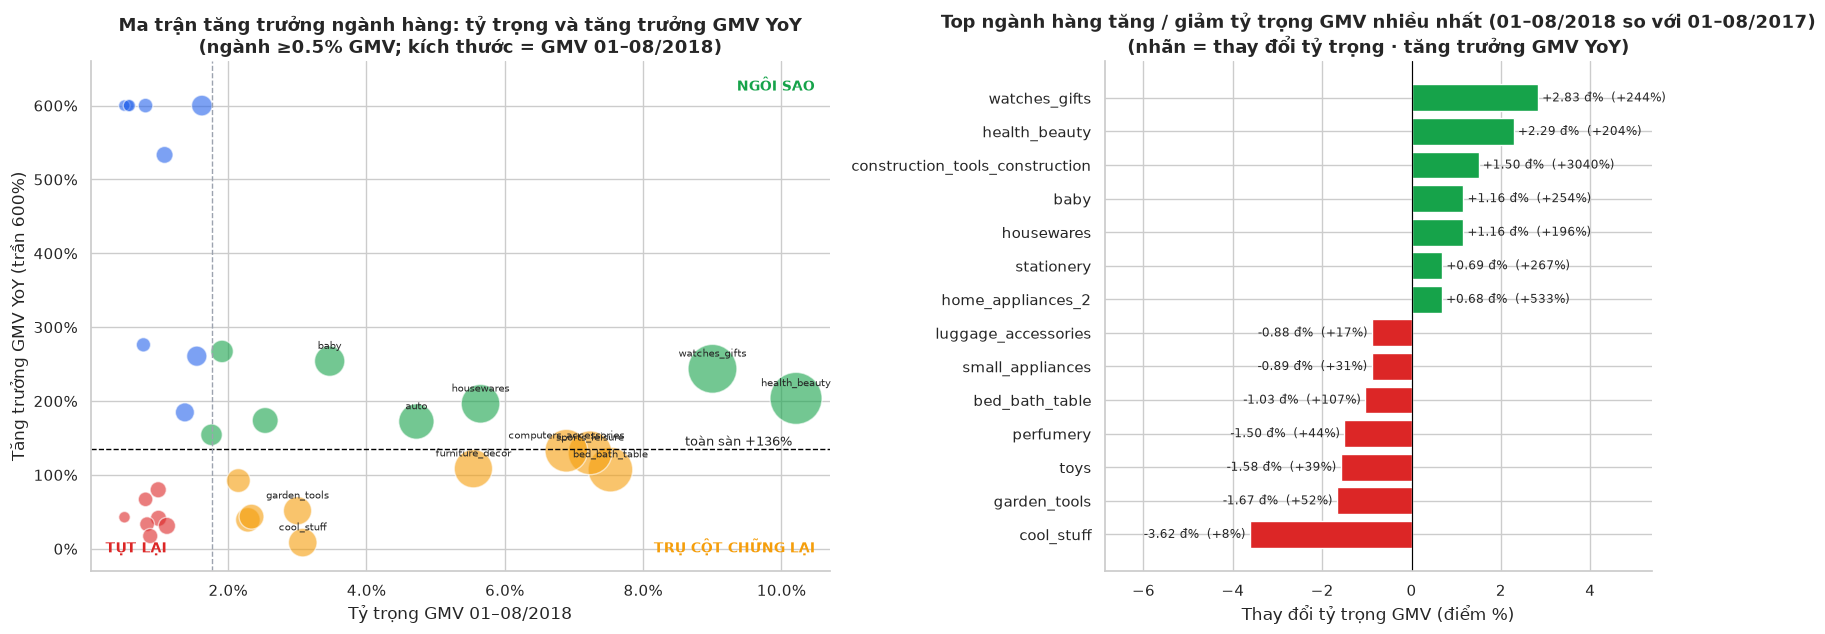

Ngưỡng tỷ trọng (trung vị): 1.76%
Ngành vượt trần:                              category  gmv_prev   gmv_cur  growth
      construction_tools_construction   4339.31 136272.93   30.40
                    home_construction   7318.21  67837.10    8.27
           agro_industry_and_commerce   5159.41  46787.96    8.07
            construction_tools_lights   1072.43  42099.97   38.26
small_appliances_home_oven_and_coffee    222.51  48173.34  215.50
                   n  share_cur                                                                                                                categories
quadrant                                                                                                                                                 
Ngôi sao           8   0.392750                                                           health_beauty, watches_gifts, housewares, auto, baby, telephony
Trụ cột chững lại  9   0.400666                          bed_bath_table, sports_leisure, co

In [6]:
category_growth = q(f"""SELECT category, sum(CASE WHEN {P.prev} THEN gmv END) AS gmv_prev, sum(CASE WHEN {P.cur} THEN gmv END) AS gmv_cur
                        FROM item_ps GROUP BY 1""").fillna(0)
category_growth["share_cur"] = category_growth.gmv_cur / category_growth.gmv_cur.sum()
category_growth["share_prev"] = category_growth.gmv_prev / category_growth.gmv_prev.sum()
category_growth["growth"] = category_growth.gmv_cur / category_growth.gmv_prev.replace(0, np.nan) - 1
category_growth["share_change_pp"] = (category_growth.share_cur - category_growth.share_prev) * 100
matrix = category_growth[(category_growth.share_cur >= MIN_CATEGORY_SHARE) & (category_growth.gmv_prev > 0)].copy()
share_cut = matrix.share_cur.median()
GROWTH_NAMES = ("Ngôi sao", "Trụ cột chững lại", "Đang lên", "Tụt lại")
GROWTH_COLORS = dict(zip(GROWTH_NAMES, [C_GOOD, C_ACCENT, C_MAIN, C_BAD]))
matrix["quadrant"] = quadrant(matrix.share_cur >= share_cut, matrix.growth >= MARKET_GROWTH, GROWTH_NAMES)
matrix["y"] = matrix.growth.clip(upper=GROWTH_AXIS_CAP)
capped = matrix[matrix.growth > GROWTH_AXIS_CAP]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.35, 1]})
ax1.scatter(matrix.share_cur, matrix.y, s=matrix.gmv_cur / matrix.gmv_cur.max() * 1400, c=matrix.quadrant.map(GROWTH_COLORS),
            alpha=0.6, edgecolor="white")
ax1.axhline(MARKET_GROWTH, color="black", ls="--", lw=1)
ax1.text(matrix.share_cur.max(), MARKET_GROWTH, f"toàn sàn {MARKET_GROWTH:+.0%} ", ha="right", va="bottom", fontsize=9)
ax1.axvline(share_cut, color=C_GREY, ls="--", lw=1)
for _, r in matrix[(matrix.share_cur >= 0.03) & (matrix.growth <= GROWTH_AXIS_CAP)].iterrows():
    ax1.annotate(r.category, (r.share_cur, r.y), fontsize=7.5, ha="center", va="bottom", xytext=(0, 7), textcoords="offset points")
ax1.set_ylim(-0.3, GROWTH_AXIS_CAP + 0.6)
pct_axis(ax1, "x"); pct_axis(ax1)
ax1.set_xlabel(f"Tỷ trọng GMV {P.label_cur}"); ax1.set_ylabel(f"Tăng trưởng GMV YoY (trần {GROWTH_AXIS_CAP:.0%})")
for (x, y, name) in [(0.98, 0.97, "Ngôi sao"), (0.98, 0.03, "Trụ cột chững lại"), (0.02, 0.03, "Tụt lại")]:
    ax1.text(x, y, name.upper(), transform=ax1.transAxes, ha="right" if x > 0.5 else "left", va="top" if y > 0.5 else "bottom",
             fontsize=10, color=GROWTH_COLORS[name], fontweight="bold")
ax1.set_title(f"Ma trận tăng trưởng ngành hàng: tỷ trọng và tăng trưởng GMV YoY\n(ngành ≥{MIN_CATEGORY_SHARE:.1%} GMV; kích thước = GMV {P.label_cur})")

share_movers = pd.concat([matrix.nlargest(7, "share_change_pp"), matrix.nsmallest(7, "share_change_pp")]).sort_values("share_change_pp")
mover_bars = ax2.barh(share_movers.category, share_movers.share_change_pp, color=np.where(share_movers.share_change_pp > 0, C_GOOD, C_BAD))
ax2.bar_label(mover_bars, labels=[f"{v:+.2f} đ%  ({g:+.0%})" for v, g in zip(share_movers.share_change_pp, share_movers.growth)],
              padding=3, fontsize=8.5)
ax2.axvline(0, color="black", lw=0.8); ax2.set_xlim(share_movers.share_change_pp.min() * 1.9, share_movers.share_change_pp.max() * 1.9)
ax2.set_xlabel("Thay đổi tỷ trọng GMV (điểm %)")
ax2.set_title(f"Top ngành hàng tăng / giảm tỷ trọng GMV nhiều nhất ({P.label_cur} so với {P.label_prev})\n(nhãn = thay đổi tỷ trọng · tăng trưởng GMV YoY)")
plt.tight_layout(); plt.show()

print(f"Ngưỡng tỷ trọng (trung vị): {share_cut:.2%}")
print("Ngành vượt trần:", capped[["category", "gmv_prev", "gmv_cur", "growth"]].round(2).to_string(index=False))
print(matrix.groupby("quadrant").agg(n=("category", "size"), share_cur=("share_cur", "sum"),
      categories=("category", lambda s: ", ".join(matrix.loc[s.index].sort_values("share_cur", ascending=False).category.head(6)))).to_string())
slower = matrix.growth < MARKET_GROWTH
print(f"\nTỷ trọng GMV {P.label_cur} của các ngành (≥{MIN_CATEGORY_SHARE:.1%}) tăng chậm hơn sàn: {matrix.share_cur[slower].sum():.1%} "
      f"({slower.sum()} ngành); riêng nhóm Trụ cột chững lại: {matrix.share_cur[matrix.quadrant == 'Trụ cột chững lại'].sum():.1%}")

gold_cat = q("SELECT category, quadrant AS gold_quadrant FROM iceberg.gold.dim_category WHERE in_matrix = 'Có'")
cmp = matrix[["category", "quadrant"]].merge(gold_cat, on="category", how="outer")
same = (cmp.quadrant == cmp.gold_quadrant).sum()
print(f"\nGóc phần tư khớp Gold: {same}/{len(cmp)} ngành (EDA {len(matrix)} ngành, Gold {len(gold_cat)} ngành trong ma trận)")
if same < len(cmp):
    print(cmp[cmp.quadrant != cmp.gold_quadrant].to_string(index=False))

> **🔎 Kết quả chính**
> - Toàn sàn tăng **+135,6%**. Chia theo ma trận (ngưỡng quy mô = trung vị 1,76% GMV):
>   - **Ngôi sao** (8 ngành, **39,3% GMV kỳ này**): health_beauty, watches_gifts, housewares, auto, baby, telephony — vừa lớn vừa giành thêm tỷ trọng → **ưu tiên đẩy ngân sách**.
>   - **Trụ cột chững lại** (9 ngành, **40,1% GMV**): bed_bath_table, sports_leisure, computers_accessories, furniture_decor, cool_stuff, garden_tools — lớn nhưng mất tỷ trọng.
>   - **Đang lên** (9 ngành, 8,8% GMV): construction_tools_construction (4,3K → 136K BRL), electronics, musical_instruments, home_appliances; vài ngành tăng hàng chục lần **từ nền gần bằng 0** (small_appliances_home_oven_and_coffee, construction_tools_lights) nên % tăng không đáng tin.
>   - **Tụt lại** (7 ngành, 6,1% GMV): small_appliances, fashion_bags_accessories, luggage_accessories, consoles_games, computers, `unknown`.
> - **16 ngành chiếm 46,2% GMV kỳ này đang tăng chậm hơn sàn.**
> - Góc phần tư khớp **33/33 ngành** với `dim_category.quadrant` của Gold.

## 4. Cơ cấu ngành hàng theo tháng
*Câu hỏi: "Tỷ trọng các ngành lớn có ổn định không? Ngành nào có nhịp riêng?"*

Lấy 8 ngành có GMV lớn nhất trong cửa sổ xu hướng (in ở §0), các ngành còn lại gom thành *Khác*.
Heatmap dùng **chỉ số tỷ trọng** = tỷ trọng của ngành trong tháng / tỷ trọng TB của chính ngành đó, để loại bỏ đà tăng chung của sàn.

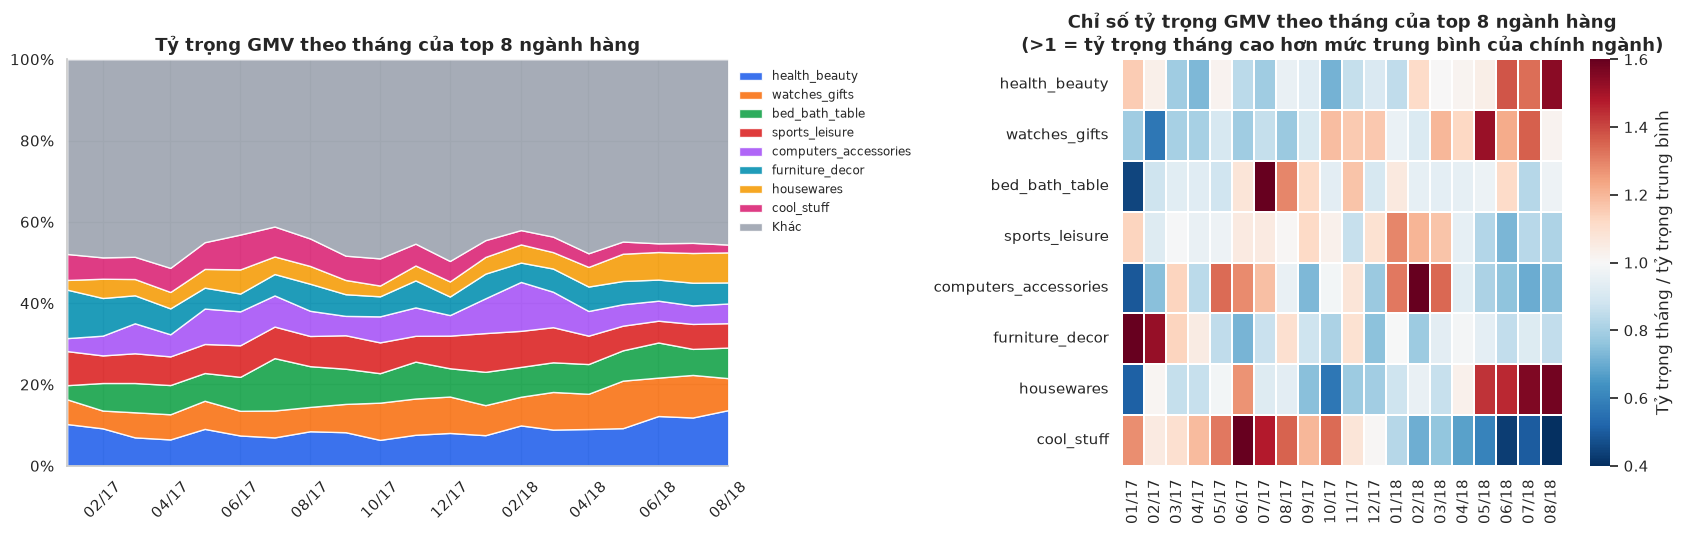

Tỷ trọng TB 01/2017–08/2018 vs tháng GMV cao nhất 11/2017:
                          TB  11/2017  chênh (đ%)
group                                            
health_beauty          0.089    0.076      -1.259
watches_gifts          0.077    0.089       1.205
bed_bath_table         0.077    0.091       1.336
sports_leisure         0.074    0.063      -1.021
computers_accessories  0.065    0.070       0.488
furniture_decor        0.061    0.066       0.562
housewares             0.047    0.037      -1.009
cool_stuff             0.050    0.054       0.381
Khác                   0.460    0.454      -0.682

Tháng có chỉ số tỷ trọng cao nhất / thấp nhất của từng ngành:
                        đỉnh  giá trị đỉnh    đáy  giá trị đáy
group                                                         
health_beauty          08/18          1.54  10/17         0.72
watches_gifts          05/18          1.52  02/17         0.57
bed_bath_table         07/17          1.66  01/17         0.45
sports_leisur

In [7]:
monthly_category = q(f"""SELECT purchase_month AS month, category, sum(gmv) AS gmv FROM item_ps
                         WHERE {P.in_period} GROUP BY 1, 2""")
monthly_category["month"] = pd.to_datetime(monthly_category.month)
top_mix_categories = monthly_category.groupby("category").gmv.sum().nlargest(TOP_CATEGORY_N).index.tolist()
monthly_category["group"] = np.where(monthly_category.category.isin(top_mix_categories), monthly_category.category, "Khác")
monthly_gmv = (monthly_category.pivot_table(index="month", columns="group", values="gmv", aggfunc="sum")
               .fillna(0)[top_mix_categories + ["Khác"]])
monthly_share = monthly_gmv.div(monthly_gmv.sum(axis=1), axis=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.2, 1]})
ax1.stackplot(monthly_share.index, monthly_share.T.values, labels=monthly_share.columns,
              colors=CATEGORY_COLORS[:TOP_CATEGORY_N] + [C_GREY], alpha=0.9)
pct_axis(ax1); ax1.set_ylim(0, 1); month_axis(ax1); ax1.set_xlim(monthly_share.index[0], monthly_share.index[-1])
ax1.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8.5, frameon=False)
ax1.set_title(f"Tỷ trọng GMV theo tháng của top {TOP_CATEGORY_N} ngành hàng")

share_index = (monthly_share[top_mix_categories] / monthly_share[top_mix_categories].mean()).T
share_index.columns = [d.strftime("%m/%y") for d in share_index.columns]
sns.heatmap(share_index, ax=ax2, cmap="RdBu_r", center=1, vmin=0.4, vmax=1.6, cbar_kws={"label": "Tỷ trọng tháng / tỷ trọng trung bình"},
            linewidths=0.3, linecolor="white")
ax2.set_xlabel(""); ax2.set_ylabel("")
ax2.set_title(f"Chỉ số tỷ trọng GMV theo tháng của top {TOP_CATEGORY_N} ngành hàng\n(>1 = tỷ trọng tháng cao hơn mức trung bình của chính ngành)")
plt.tight_layout(); plt.show()

# Tháng GMV cao nhất của sàn (với dữ liệu hiện tại là 11/2017 – Black Friday) có làm đổi cơ cấu ngành không?
avg_share = monthly_share.mean()
peak_month = monthly_gmv.sum(axis=1).idxmax(); peak_share = monthly_share.loc[peak_month]
print(f"Tỷ trọng TB {P.label_trend} vs tháng GMV cao nhất {peak_month:%m/%Y}:")
print(pd.DataFrame({"TB": avg_share, f"{peak_month:%m/%Y}": peak_share, "chênh (đ%)": (peak_share - avg_share) * 100}).round(3).to_string())
print("\nTháng có chỉ số tỷ trọng cao nhất / thấp nhất của từng ngành:")
print(pd.DataFrame({"đỉnh": share_index.idxmax(axis=1), "giá trị đỉnh": share_index.max(axis=1).round(2),
                    "đáy": share_index.idxmin(axis=1), "giá trị đáy": share_index.min(axis=1).round(2)}).to_string())
first_6m, last_6m = monthly_share.iloc[:6].mean(), monthly_share.iloc[-6:].mean()
first_label = f"{monthly_share.index[0]:%m/%Y}–{monthly_share.index[5]:%m/%Y}"
last_label = f"{monthly_share.index[-6]:%m/%Y}–{monthly_share.index[-1]:%m/%Y}"
print(f"\nTỷ trọng TB 6 tháng đầu ({first_label}) vs 6 tháng cuối ({last_label}):")
print(pd.DataFrame({"đầu": first_6m, "cuối": last_6m, "chênh (đ%)": (last_6m - first_6m) * 100}).round(3).sort_values("chênh (đ%)").to_string())

> **🔎 Kết quả chính**
> - **Cơ cấu thay đổi theo xu hướng nhiều hơn theo mùa vụ.** So 01–06/2017 với 03–08/2018: watches_gifts 6,0% → **9,6%**, health_beauty 8,3% → **10,8%**, housewares 4,3% → 6,2%; ngược lại **cool_stuff 6,4% → 2,8%**, furniture_decor 7,3% → 5,6%.
> - **Black Friday 11/2017 không làm đổi cơ cấu**: các ngành lớn chỉ lệch ±1,3 điểm % so với tỷ trọng trung bình — cả sàn tăng, không riêng ngành nào.
> - **computers_accessories** và **sports_leisure** mạnh bất thường đầu 2018 (computers_accessories 02/2018 gấp 1,85 lần tỷ trọng TB; sports_leisure đỉnh 01/2018).

## 5. Phân khúc giá sản phẩm
*Câu hỏi: "Doanh thu đến từ hàng rẻ hay hàng đắt? Phí ship chiếm bao nhiêu ở mỗi tầng giá?"*

Chia **giá bán 1 đơn vị** (`price`) thành 6 tầng. Lưu ý: đây là tầng giá **của sản phẩm**, khác với tầng **giá trị đơn hàng**
(`Order Value Band`) ở `04_customer` §5. So sánh tỷ trọng **số sản phẩm đã bán** với tỷ trọng **GMV**, và **phí ship / GMV** trong từng tầng.

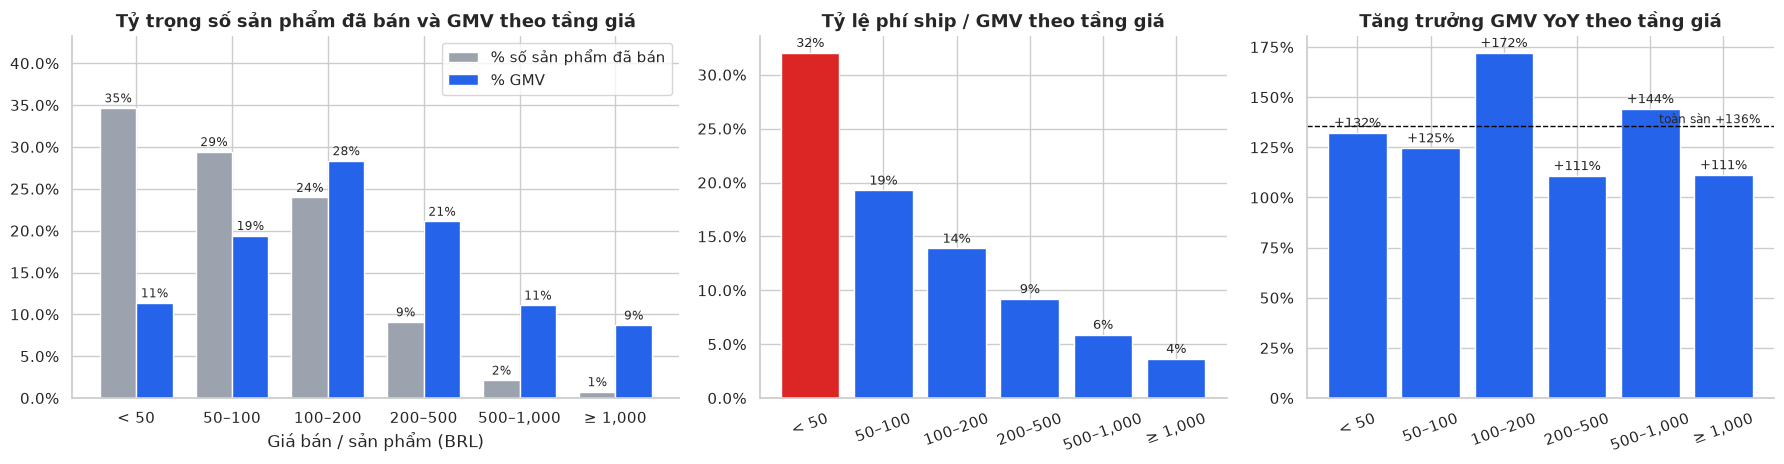

     band  units  unit_share        gmv  gmv_share  freight_share  growth  skus  sellers
     < 50  38288       0.346 1763877.55      0.114          0.320   1.323 11277     1708
   50–100  32521       0.294 3012867.34      0.194          0.193   1.246  8881     1705
  100–200  26478       0.240 4400519.42      0.283          0.139   1.721  7792     1603
  200–500  10043       0.091 3276681.57      0.211          0.092   1.108  3984     1107
500–1,000   2348       0.021 1721224.28      0.111          0.059   1.442  1078      416
  ≥ 1,000    822       0.007 1350836.25      0.087          0.037   1.112   445      197



Giá trung vị / đơn vị: R$ 75.0; giá TB: R$ 120.5


In [8]:
price_band_sql = "CASE " + " ".join(f"WHEN price < {hi} THEN {i}" for i, hi in enumerate(PRICE_EDGES[1:-1])) + f" ELSE {len(PRICE_EDGES) - 2} END"
price_bands = q(f"""SELECT {price_band_sql} AS band, count(*) AS units, sum(gmv) AS gmv, sum(freight_value) AS freight,
                           count(DISTINCT seller_key) AS sellers, count(DISTINCT product_id) AS skus,
                           sum(CASE WHEN {P.prev} THEN gmv END) AS gmv_prev, sum(CASE WHEN {P.cur} THEN gmv END) AS gmv_cur
                    FROM item_ps GROUP BY 1 ORDER BY 1""")
price_bands["band"] = [PRICE_LABELS[i] for i in price_bands.band]
price_bands["unit_share"] = price_bands.units / price_bands.units.sum()
price_bands["gmv_share"] = price_bands.gmv / price_bands.gmv.sum()
price_bands["freight_share"] = price_bands.freight / price_bands.gmv
price_bands["growth"] = price_bands.gmv_cur / price_bands.gmv_prev - 1

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 4.8), gridspec_kw={"width_ratios": [1.3, 1, 1]})
share_bars(ax1, price_bands.band, price_bands.unit_share, price_bands.gmv_share, "% số sản phẩm đã bán")
ax1.set_xlabel("Giá bán / sản phẩm (BRL)"); ax1.set_title("Tỷ trọng số sản phẩm đã bán và GMV theo tầng giá")

x = np.arange(len(price_bands))
freight_bars = ax2.bar(x, price_bands.freight_share, color=[C_BAD if v > 0.2 else C_MAIN for v in price_bands.freight_share])
ax2.bar_label(freight_bars, labels=[f"{v:.0%}" for v in price_bands.freight_share], fontsize=9, padding=2)
ax2.set_xticks(x, price_bands.band, rotation=20); pct_axis(ax2); ax2.set_title("Tỷ lệ phí ship / GMV theo tầng giá")

growth_bars = ax3.bar(x, price_bands.growth, color=C_MAIN)
ax3.bar_label(growth_bars, labels=[f"{v:+.0%}" for v in price_bands.growth], fontsize=9, padding=2)
ax3.axhline(MARKET_GROWTH, color="black", ls="--", lw=1)
ax3.text(len(price_bands) - 0.5, MARKET_GROWTH, f"toàn sàn {MARKET_GROWTH:+.0%}", ha="right", va="bottom", fontsize=8.5)
ax3.set_xticks(x, price_bands.band, rotation=20); pct_axis(ax3); ax3.set_title("Tăng trưởng GMV YoY theo tầng giá")
plt.tight_layout(); plt.show()

print(price_bands[["band", "units", "unit_share", "gmv", "gmv_share", "freight_share", "growth", "skus", "sellers"]].round(3).to_string(index=False))
unit_price_median = q(f"SELECT {median_sql('price')} AS m FROM item_ps").m[0]
print(f"\nGiá trung vị / đơn vị: R$ {unit_price_median:.1f}; "
      f"giá TB: R$ {q('SELECT avg(price) AS m FROM item_ps').m[0]:.1f}")

> **🔎 Kết quả chính**
> - Giá trung vị chỉ **R$ 75 / đơn vị** (TB R$ 120,5): sàn chủ yếu bán **hàng giá thấp**.
> - Số lượng và doanh thu lệch nhau mạnh: hàng **< 100 BRL = 64% số sản phẩm nhưng chỉ 31% GMV**; hàng **≥ 200 BRL = 12% số sản phẩm nhưng 41% GMV**. Tầng **100–200 BRL** đóng góp GMV lớn nhất (**28%**).
> - **Phí ship chiếm 32% GMV ở tầng < 50 BRL** và 19% ở tầng 50–100, so với 4–6% ở hàng ≥ 500 BRL: với hàng rẻ, khách trả gần 1 đồng ship cho mỗi 2 đồng hàng.
> - Tăng trưởng nghiêng về **tầng giữa**: 100–200 BRL **+172%**, 500–1.000 BRL +144%, vượt sàn; các tầng còn lại +111% đến +132%.

## 6. Chất lượng theo ngành hàng
*Câu hỏi: "Ngành hàng lớn nào doanh thu cao nhưng chất lượng kém? Do sản phẩm hay do giao hàng? Hàng cồng kềnh có gắn với giao trễ không?"*

- Một đơn có thể có nhiều ngành, nên chỉ số của đơn được gán cho từng cặp *(đơn, ngành)* không trùng lặp. Tính trên **mọi đơn của kỳ này**
  (để có tỷ lệ hủy); điểm review, % không hài lòng chỉ tính đơn có review; % trễ, số ngày giao chỉ tính đơn đã giao đủ ngày.
- Biểu đồ đầu dựng lại visual *Doanh thu và chất lượng sản phẩm – Top 15 ngành* của p2.
- **Giả thuyết hàng cồng kềnh**: dữ liệu không có thông tin hư hỏng, nên chỉ kiểm tra *trọng lượng sản phẩm* (`product_weight_g`) có đi cùng giao chậm / trễ / không hài lòng không.
  Các tầng trọng lượng dưới đây là **ngưỡng EDA, không có trên Power BI**.

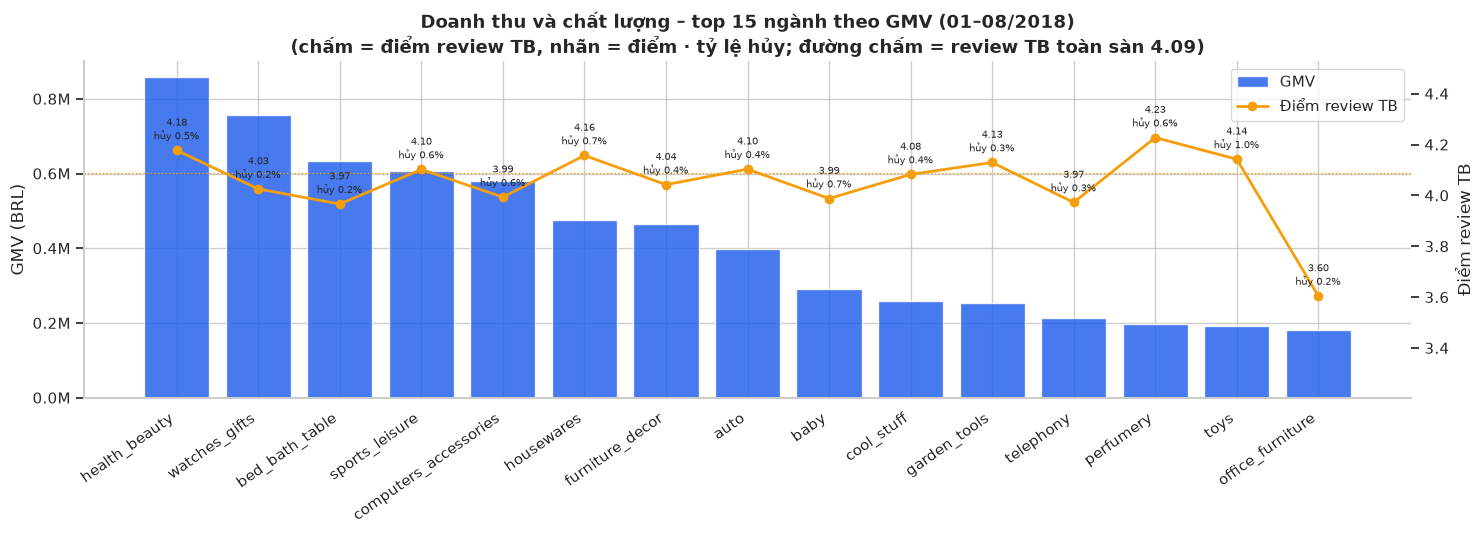

In [9]:
CX_METRICS = "count(*) AS orders, avg(review_score) AS avg_score, avg(is_negative) AS negative_rate"
cat_q = q(f'''
    WITH order_cat AS (
        SELECT DISTINCT i.order_key, {CATEGORY_SQL} AS category
        FROM fact_order_items i
        JOIN dim_product p ON p.product_key = i.product_key
        LEFT JOIN dim_category cat ON cat.category_key = p.category_key)
    SELECT category, {CX_METRICS}, avg(is_lost) AS cancel_rate, avg(is_late) AS late_rate,
           avg(CASE WHEN is_delivered = 1 THEN delivery_days END) AS avg_delivery_days
    FROM order_cat JOIN order_base USING (order_key)
    WHERE {P.cur}
    GROUP BY 1''')
gmv_cur = q(f"SELECT category, sum(gmv) AS gmv FROM item_ps WHERE {P.cur} GROUP BY 1")
cat_q = cat_q.merge(gmv_cur, on="category", how="left").sort_values("gmv", ascending=False)
avg_review = scalar(f"SELECT avg(review_score) FROM order_base WHERE {P.cur}")

top15 = cat_q.head(15)
fig, ax = plt.subplots(figsize=(15, 5.5))
x = np.arange(len(top15))
ax.bar(x, top15.gmv, color=C_MAIN, alpha=0.85, label="GMV")
brl_axis(ax); ax.set_xticks(x, top15.category, rotation=35, ha="right"); ax.set_ylabel("GMV (BRL)")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot(x, top15.avg_score, color=C_ACCENT, marker="o", lw=2, label="Điểm review TB")
ax2.axhline(avg_review, color=C_ACCENT, ls=":", lw=1)
for i, (s, c) in enumerate(zip(top15.avg_score, top15.cancel_rate)):
    ax2.annotate(f"{s:.2f}\nhủy {c:.1%}", (i, s), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=7.5)
ax2.set_ylim(top15.avg_score.min() - 0.4, top15.avg_score.max() + 0.3); ax2.set_ylabel("Điểm review TB")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper right")
ax.set_title(f"Doanh thu và chất lượng – top 15 ngành theo GMV ({P.label_cur})\n"
             f"(chấm = điểm review TB, nhãn = điểm · tỷ lệ hủy; đường chấm = review TB toàn sàn {avg_review:.2f})")
plt.tight_layout(); plt.show()

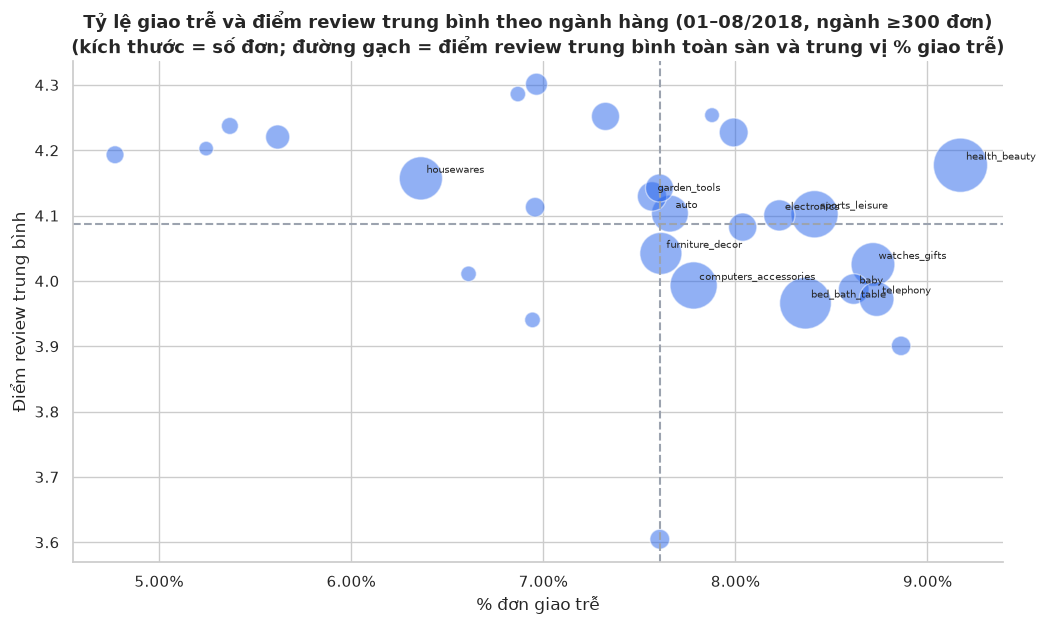

                       category  orders  avg_score  negative_rate  cancel_rate  late_rate  avg_delivery_days       gmv
                  health_beauty    5254      4.177          0.129        0.005      0.092             11.435 857676.08
                  watches_gifts    3403      4.025          0.162        0.002      0.087             12.653 756228.95
                 bed_bath_table    4774      3.966          0.172        0.002      0.084             11.824 632315.78
                 sports_leisure    3983      4.102          0.148        0.006      0.084             11.679 607549.58
          computers_accessories    3974      3.993          0.169        0.006      0.078             13.006 578827.08
                     housewares    3322      4.157          0.132        0.007      0.064             10.225 474597.60
                furniture_decor    3139      4.042          0.162        0.004      0.076             11.989 465939.80
                           auto    2401      4.1

In [10]:
big_cat = cat_q[cat_q.orders >= 300]
fig, ax = plt.subplots(figsize=(12, 6.5))
ax.scatter(big_cat.late_rate, big_cat.avg_score, s=big_cat.orders / big_cat.orders.max() * 1500 + 20,
           color=C_MAIN, alpha=0.5, edgecolor="white")
ax.axhline(avg_review, color=C_GREY, ls="--"); ax.axvline(big_cat.late_rate.median(), color=C_GREY, ls="--")
pct_axis(ax, "x"); ax.set_xlabel("% đơn giao trễ"); ax.set_ylabel("Điểm review trung bình")
ax.set_title(f"Tỷ lệ giao trễ và điểm review trung bình theo ngành hàng ({P.label_cur}, ngành ≥300 đơn)\n"
             "(kích thước = số đơn; đường gạch = điểm review trung bình toàn sàn và trung vị % giao trễ)")
for _, r in big_cat.nlargest(12, 'orders').iterrows():
    ax.annotate(r.category, (r.late_rate, r.avg_score), fontsize=7.5, xytext=(4, 4), textcoords='offset points')
plt.show()
print(cat_q.head(25).round(3).to_string(index=False))

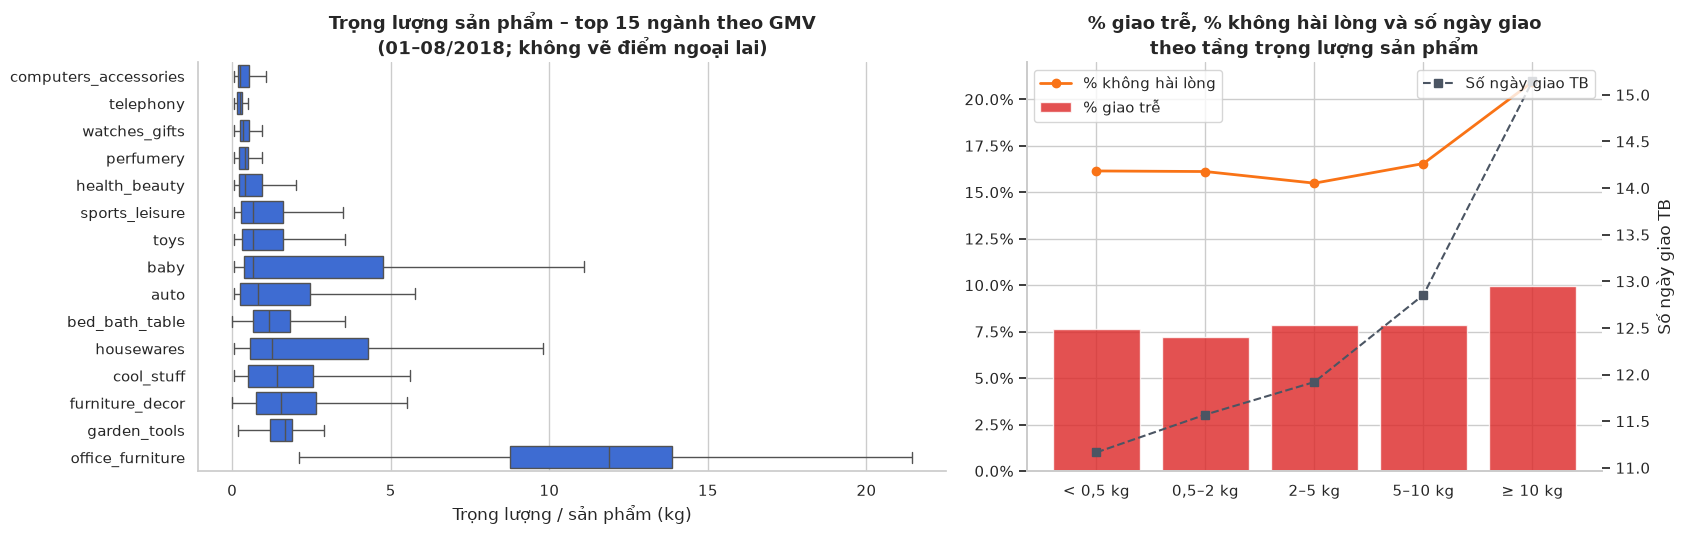

weight_band  items  avg_delivery_days  late_rate  negative_rate  freight_to_price
   < 0,5 kg  25197             11.165      0.076          0.161             0.409
   0,5–2 kg  21202             11.571      0.072          0.161             0.274
     2–5 kg   6030             11.920      0.078          0.155             0.213
    5–10 kg   4467             12.855      0.079          0.165             0.254
    ≥ 10 kg   2789             15.148      0.100          0.209             0.260

Tương quan (top 15 ngành) giữa trọng lượng trung vị và % trễ: -0.25; và số ngày giao TB: +0.94
             category  median_kg  avg_delivery_days  late_rate  negative_rate  avg_score
     office_furniture     11.875             21.588      0.076          0.236      3.605
         garden_tools      1.650             12.591      0.076          0.134      4.129
      furniture_decor      1.550             11.989      0.076          0.162      4.042
           cool_stuff      1.400             12.334     

In [11]:
# Giả thuyết hàng cồng kềnh: trọng lượng sản phẩm vs giao chậm / trễ / không hài lòng (dòng sản phẩm của đơn hợp lệ kỳ này)
WEIGHT_BINS = [(500, "< 0,5 kg"), (2000, "0,5–2 kg"), (5000, "2–5 kg"), (10000, "5–10 kg")]   # ngưỡng EDA
WEIGHT_LAST = "≥ 10 kg"
WEIGHT_ORDER = [label for _, label in WEIGHT_BINS] + [WEIGHT_LAST]
con.execute(f'''
CREATE OR REPLACE TABLE item_weight AS
SELECT i.category, p.product_weight_g AS weight_g, {band_sql("p.product_weight_g", WEIGHT_BINS, WEIGHT_LAST)} AS weight_band,
       o.delivery_days, o.is_late, o.is_negative, i.freight_value / nullif(i.price, 0) AS freight_to_price
FROM item_ps i
JOIN dim_product p ON p.product_key = i.product_key
JOIN order_base o ON o.order_key = i.order_key
WHERE {P.cur_on("i.purchase_month")} AND p.product_weight_g IS NOT NULL''')
by_weight = ordered(q('''SELECT weight_band, count(*) AS items, avg(delivery_days) AS avg_delivery_days, avg(is_late) AS late_rate,
                               avg(is_negative) AS negative_rate, avg(freight_to_price) AS freight_to_price
                        FROM item_weight GROUP BY 1'''), "weight_band", WEIGHT_ORDER)

top_cats = cat_q.head(15).category.tolist()
w = q(f"SELECT category, weight_g / 1000.0 AS weight_kg FROM item_weight WHERE category IN ({', '.join(repr(c) for c in top_cats)})")
order_by_median = w.groupby("category").weight_kg.median().sort_values().index.tolist()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 5.5), gridspec_kw={"width_ratios": [1.3, 1]})
sns.boxplot(data=w, y="category", x="weight_kg", order=order_by_median, color=C_MAIN, showfliers=False, ax=ax1)
ax1.set_xlabel("Trọng lượng / sản phẩm (kg)"); ax1.set_ylabel("")
ax1.set_title(f"Trọng lượng sản phẩm – top 15 ngành theo GMV\n({P.label_cur}; không vẽ điểm ngoại lai)")
xw = np.arange(len(by_weight))
ax2.bar(xw, by_weight.late_rate, color=C_BAD, alpha=0.8, label="% giao trễ")
ax2.plot(xw, by_weight.negative_rate, color=C_ORANGE, marker="o", lw=2, label="% không hài lòng")
pct_axis(ax2); ax2.set_xticks(xw, by_weight.weight_band); ax2.legend(loc="upper left")
ax3 = ax2.twinx(); ax3.grid(False)
ax3.plot(xw, by_weight.avg_delivery_days, color=C_MUTED_TEXT, marker="s", ls="--", lw=1.5, label="Số ngày giao TB")
ax3.set_ylabel("Số ngày giao TB"); ax3.legend(loc="upper right")
ax2.set_title("% giao trễ, % không hài lòng và số ngày giao\ntheo tầng trọng lượng sản phẩm")
plt.tight_layout(); plt.show()

print(by_weight.round(3).to_string(index=False))
cat_weight = w.groupby("category").weight_kg.median().rename("median_kg").reset_index().merge(cat_q, on="category")
print(f"\nTương quan (top 15 ngành) giữa trọng lượng trung vị và % trễ: {cat_weight.median_kg.corr(cat_weight.late_rate):+.2f}; "
      f"và số ngày giao TB: {cat_weight.median_kg.corr(cat_weight.avg_delivery_days):+.2f}")
print(cat_weight.sort_values("median_kg", ascending=False)[["category", "median_kg", "avg_delivery_days", "late_rate", "negative_rate", "avg_score"]]
      .round(3).to_string(index=False))

> **🔎 Kết quả chính**
> - Trong top 15 ngành theo GMV kỳ này, **office_furniture kém nhất xa** (★3,60, 23,6% đơn không hài lòng, giao TB 21,6 ngày); bed_bath_table, telephony (★3,97), baby, computers_accessories (★3,99) cũng dưới mức chung của sàn (4,09). Ngành lớn nhất health_beauty và housewares, perfumery, toys đều trên mức chung.
> - **Tỷ lệ hủy không phân biệt ngành**: mọi ngành lớn đều ≤ 1% → không phải tiêu chí chọn ngành.
> - **Giả thuyết hàng cồng kềnh chỉ đúng với hàng rất nặng**: số ngày giao tăng đều theo trọng lượng (11,2 ngày ở < 0,5 kg → 15,1 ngày ở ≥ 10 kg), nhưng % trễ (7–8%) và % không hài lòng (~16%) gần như phẳng cho tới 10 kg; chỉ tầng **≥ 10 kg** (~5% sản phẩm) nhảy lên 10,0% trễ và **20,9% không hài lòng**.
> - Giữa 15 ngành, trọng lượng trung vị gắn rất chặt với số ngày giao (**+0,94**, do office_furniture nặng 11,9 kg) nhưng không gắn với % trễ (−0,25): hàng nặng được *hứa* giao lâu hơn nên ít khi trễ, song chờ lâu vẫn làm khách không hài lòng.
> - → Với quyết định ②: đẩy **Ngôi sao** (health_beauty, watches_gifts, housewares…) an toàn về chất lượng; đẩy office_furniture / hàng ≥ 10 kg chỉ khi có giải pháp giao hàng riêng.

## 7. Danh mục sản phẩm & đuôi dài
*Câu hỏi: "Doanh thu dựa vào vài sản phẩm 'hit' hay vào hàng chục nghìn sản phẩm bán lẻ tẻ?"*

Phân nhóm SKU theo **tổng số sản phẩm đã bán** trong toàn kỳ và đo đóng góp GMV của từng nhóm.

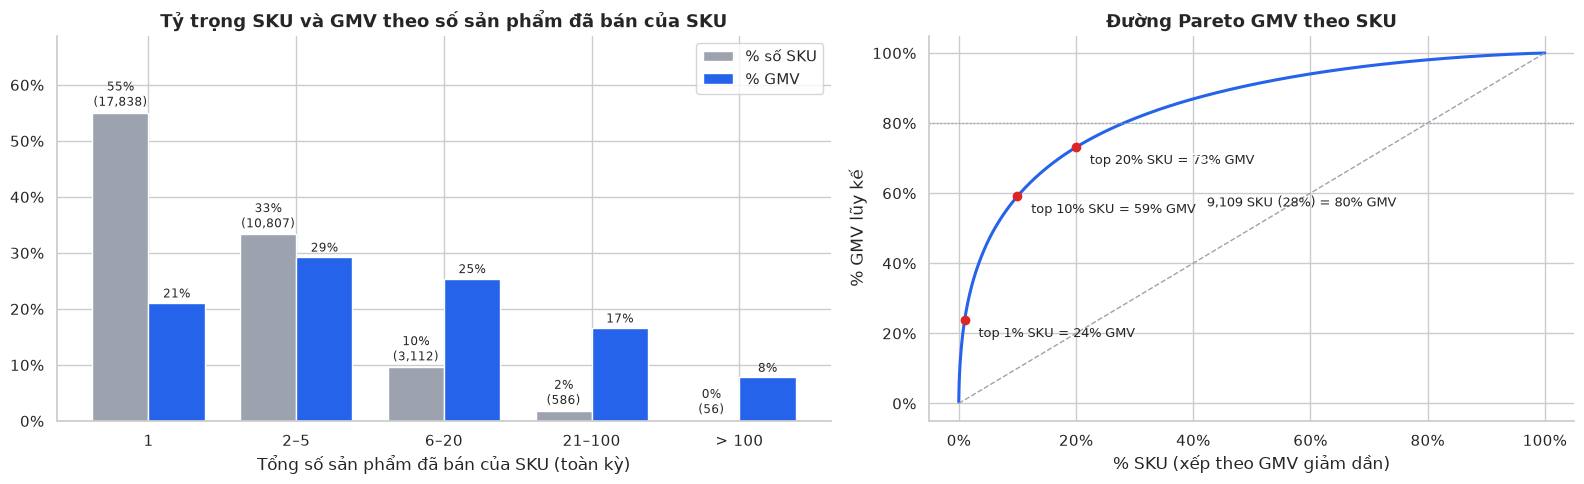

            skus         gmv  sku_share  gmv_share
unit_band                                         
1          17838  3267184.51      0.551      0.210
2–5        10807  4538722.02      0.334      0.292
6–20        3112  3942328.97      0.096      0.254
21–100       586  2572460.60      0.018      0.166
> 100         56  1205310.31      0.002      0.078

32,399 SKU; trung vị 1 sản phẩm / SKU; SKU bán ≥ 2 sản phẩm: 44.9% số SKU; top 1 SKU = 0.43% GMV; top 100 SKU = 13.3% GMV; 9,109 SKU (28.1%) = 80% GMV
SKU do ≥2 người bán cùng bán: 3.7% số SKU, 13.2% GMV


In [12]:
skus = q("""SELECT product_id, arbitrary(category) AS category, count(*) AS units, sum(gmv) AS gmv,
                   count(DISTINCT seller_key) AS sellers, avg(price) AS avg_price
            FROM item_ps GROUP BY 1 ORDER BY gmv DESC""")
skus["cum_share"] = skus.gmv.cumsum() / skus.gmv.sum()
skus["pct_skus"] = np.arange(1, len(skus) + 1) / len(skus)
skus["unit_band"] = pd.cut(skus.units, SKU_UNIT_EDGES, labels=SKU_UNIT_LABELS)
sku_bands = skus.groupby("unit_band", observed=False).agg(skus=("product_id", "size"), gmv=("gmv", "sum"))
sku_bands["sku_share"] = sku_bands.skus / sku_bands.skus.sum(); sku_bands["gmv_share"] = sku_bands.gmv / sku_bands.gmv.sum()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.2, 1]})
share_bars(ax1, sku_bands.index, sku_bands.sku_share, sku_bands.gmv_share, "% số SKU",
           left_text=[f"{v:.0%}\n({n:,})" for v, n in zip(sku_bands.sku_share, sku_bands.skus)])
ax1.set_xlabel("Tổng số sản phẩm đã bán của SKU (toàn kỳ)")
ax1.set_title("Tỷ trọng SKU và GMV theo số sản phẩm đã bán của SKU")

ax2.plot(skus.pct_skus, skus.cum_share, color=C_MAIN, lw=2.2); ax2.plot([0, 1], [0, 1], color=C_GREY, ls="--", lw=1)
for top_pct in (0.01, 0.1, 0.2):
    v = skus.cum_share.iloc[int(len(skus) * top_pct) - 1]
    ax2.scatter([top_pct], [v], color=C_BAD, zorder=3)
    ax2.annotate(f"top {top_pct:.0%} SKU = {v:.0%} GMV", (top_pct, v), xytext=(10, -12), textcoords="offset points", fontsize=9)
n_skus_80 = (skus.cum_share < 0.8).sum() + 1
ax2.axhline(0.8, color=C_GREY, ls=":", lw=1)
ax2.annotate(f"{n_skus_80:,} SKU ({n_skus_80 / len(skus):.0%}) = 80% GMV", (n_skus_80 / len(skus), 0.8), xytext=(60, -60),
             textcoords="offset points", fontsize=9, arrowprops=dict(arrowstyle="->"))
pct_axis(ax2); pct_axis(ax2, "x"); ax2.set_xlabel("% SKU (xếp theo GMV giảm dần)"); ax2.set_ylabel("% GMV lũy kế")
ax2.set_title("Đường Pareto GMV theo SKU")
plt.tight_layout(); plt.show()

print(sku_bands.round(3).to_string())
print(f"\n{len(skus):,} SKU; trung vị {skus.units.median():.0f} sản phẩm / SKU; SKU bán ≥ 2 sản phẩm: {(skus.units >= 2).mean():.1%} số SKU; "
      f"top 1 SKU = {skus.gmv.iloc[0] / skus.gmv.sum():.2%} GMV; top 100 SKU = {skus.gmv.head(100).sum() / skus.gmv.sum():.1%} GMV; "
      f"{n_skus_80:,} SKU ({n_skus_80 / len(skus):.1%}) = 80% GMV")
multi_seller = skus.sellers >= 2
print(f"SKU do ≥2 người bán cùng bán: {multi_seller.mean():.1%} số SKU, {skus.gmv[multi_seller].sum() / skus.gmv.sum():.1%} GMV")

> **🔎 Kết quả chính**
> - Olist là sàn **đuôi dài điển hình**: 32.399 SKU, **trung vị chỉ 1 sản phẩm đã bán / SKU**. 55% SKU chỉ bán đúng 1 lần nhưng vẫn tạo **21% GMV**; SKU bán ≤ 5 sản phẩm tạo **50% GMV**.
> - **Không có sản phẩm "hit"**: SKU lớn nhất chỉ 0,43% GMV, top 100 SKU = 13,3%. Cần **9.109 SKU (28%)** để đạt 80% GMV; chỉ 56 SKU bán > 100 sản phẩm (7,8% GMV).
> - Gần như mọi SKU chỉ có 1 người bán (SKU có ≥ 2 người bán: 3,7% SKU, 13,2% GMV) → **cạnh tranh giá trên cùng sản phẩm rất ít**. Sức mạnh doanh thu nằm ở **độ rộng danh mục**.

## 8. Đối chiếu với Gold (nguồn của Power BI)
Các thẻ KPI của trang p2 tính lại từ Silver phải khớp Gold: GMV ngành hàng từ `fact_item_sales`, review và tỷ lệ hủy từ `fact_order_summary`.

In [13]:
GI, GO = "iceberg.gold.fact_item_sales", "iceberg.gold.fact_order_summary"
gcur, gprev, gq, gpq = (gold_period_where(w) for w in (P.cur, P.prev, P.qtd, P.pqtd))
growth = lambda col, a, b: f"sum(CASE WHEN {a} THEN {col} END) / sum(CASE WHEN {b} THEN {col} END) - 1"
k = product_kpis(P.cur)
reconcile([
    ("GMV ngành hàng kỳ này", k["gmv"], f"SELECT sum(item_gmv) FROM {GI} WHERE {gcur}"),
    ("Tăng trưởng YoY", scalar(f"SELECT {growth('gmv', P.cur, P.prev)} FROM item_ps"), f"SELECT {growth('item_gmv', gcur, gprev)} FROM {GI}"),
    ("Tăng trưởng QoQ", scalar(f"SELECT {growth('gmv', P.qtd, P.pqtd)} FROM item_ps"), f"SELECT {growth('item_gmv', gq, gpq)} FROM {GI}"),
    ("Điểm review TB", k["avg_review"], f"SELECT avg(review_score) FROM {GO} WHERE is_valid = 1 AND {gcur}"),
    ("Tỷ lệ hủy đơn", k["cancel_rate"], f"SELECT avg(CAST(order_status IN ('canceled', 'unavailable') AS DOUBLE)) FROM {GO} WHERE {gcur}"),
    ("Số ngành trong ma trận", len(matrix), "SELECT count(*) FROM iceberg.gold.dim_category WHERE in_matrix = 'Có'"),
])

,EDA (Silver),Gold,Sai lệch,Khớp
Chỉ số,,,,
GMV ngành hàng kỳ này,"8,398,428","8,398,428",4.44e-15,True
Tăng trưởng YoY,1.3561,1.3561,2.16e-14,True
Tăng trưởng QoQ,-0.1296,-0.1296,1.77e-13,True
Điểm review TB,4.1077,4.1077,2.16e-16,True
Tỷ lệ hủy đơn,0.0087,0.0087,0.00e+00,True
Số ngành trong ma trận,33,33,0.00e+00,True


## 9. Đánh giá & tuyển chọn visual cho trang p2
Tiêu chí đưa lên Power BI: đọc hiểu trong ~10 giây, dẫn tới quyết định ② (tập trung ngành nào), còn đúng khi lọc bằng slicer.

| Biểu đồ EDA | Câu hỏi / quyết định | Visual Power BI tương ứng (p2) hoặc "Phụ lục" | Lý do |
|---|---|---|---|
| §1 Bảng KPI sản phẩm | Quy mô, tăng trưởng, chất lượng | Thẻ *GMV ngành hàng*, *Tăng trưởng QoQ*, *Tăng trưởng YoY*, *Điểm review TB*, *Tỷ lệ hủy đơn* | Các chỉ số SKU / giá TB để ở notebook |
| §3 Ma trận tỷ trọng × tăng trưởng | **Ngành nào là trụ cột / đang lên / tụt lại** | *Ma trận tăng trưởng ngành* | Trả lời thẳng quyết định ②; góc phần tư khớp `dim_category.quadrant` |
| §3 Top ngành tăng/giảm tỷ trọng | Ai đang giành thị phần | Phụ lục (tooltip ma trận) | Trùng thông tin với ma trận |
| §6 GMV + review + hủy, top 15 ngành | Ngành lớn nào chất lượng kém | *Doanh thu và chất lượng sản phẩm – Top 15 ngành* | Đặt doanh thu cạnh chất lượng để không đẩy ngân sách vào ngành gây bất mãn |
| §5 Số sản phẩm vs GMV vs phí ship theo tầng giá | Hàng rẻ hay đắt tạo doanh thu | *Sản lượng và doanh thu theo tầng giá* | Cho thấy nghịch lý hàng rẻ: nhiều đơn vị, ít GMV, phí ship nặng |
| §2 Top 15 ngành theo GMV, bản đồ số lượng × giá | Ngành bán nhờ lượng hay giá | *Cấu trúc giá và phí ship theo ngành hàng* (tách tiền hàng / phí ship) | Bản đồ lượng × giá để ở notebook |
| §4 Cơ cấu ngành theo tháng, chỉ số tỷ trọng | Mùa vụ hay xu hướng | Phụ lục | Kết luận "xu hướng hơn mùa vụ" dùng để giải trình |
| §6 Giao trễ × review theo ngành, trọng lượng × giao trễ | Vì sao ngành X kém | Phụ lục | Bằng chứng khi HĐQT hỏi "tại sao" |
| §7 Đuôi dài SKU | Dựa vào hit hay độ rộng | Phụ lục | Không đổi quyết định chọn ngành |

In [14]:
con.close()